# 02 — Duplicatas: KPMG

Ciência de Dados — Atividade 05: Revisão

Autor: Carlos Gabriel Raposo Landim

Base real: [Customer Transaction Dataset — Kaggle](https://www.kaggle.com/datasets/archit9406/customer-transaction-dataset)

Os arquivos originais estão em `dados/`. As células foram executadas na ordem apresentada. Cada estratégia usa uma cópia; resultados experimentais não são evidência de qualidade preditiva. Em modelos, separar treino/teste antes de ajustar imputadores e escalonadores.

## Importações, carregamento e conferência do cabeçalho

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2})
DADOS = Path('dados')
RESULTADOS = Path('resultados')
RESULTADOS.mkdir(exist_ok=True)
arquivo = DADOS/'kpmg/KPMG_VI_New_raw_data_update_final.xlsx'
display(pd.read_excel(arquivo,sheet_name='Transactions',header=None,nrows=4))
df = pd.read_excel(arquivo,sheet_name='Transactions',header=1)
original = df.copy(deep=True)
print('Dimensões:',df.shape)
display(df.head())
display(pd.DataFrame({'tipo':df.dtypes.astype(str),'ausentes':df.isna().sum()}))
assert 'transaction_id' in df.columns

Dimensões: (20000, 13)


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,Note: The data and information in this documen...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,transaction_id,product_id,customer_id,transaction_date,online_order,order_status,brand,product_line,product_class,product_size,list_price,standard_cost,product_first_sold_date
2,1,2,2950,2017-02-25 00:00:00,False,Approved,Solex,Standard,medium,medium,71.49,53.62,41245
3,2,3,3120,2017-05-21 00:00:00,True,Approved,Trek Bicycles,Standard,medium,large,2091.47,388.92,41701


,transaction_id,product_id,customer_id,transaction_date,online_order,order_status,brand,product_line,product_class,product_size,list_price,standard_cost,product_first_sold_date
0,1,2,2950,2017-02-25,0.0,Approved,Solex,Standard,medium,medium,71.49,53.62,41245.0
1,2,3,3120,2017-05-21,1.0,Approved,Trek Bicycles,Standard,medium,large,2091.47,388.92,41701.0
2,3,37,402,2017-10-16,0.0,Approved,OHM Cycles,Standard,low,medium,1793.43,248.82,36361.0
3,4,88,3135,2017-08-31,0.0,Approved,Norco Bicycles,Standard,medium,medium,1198.46,381.10,36145.0
4,5,78,787,2017-10-01,1.0,Approved,Giant Bicycles,Standard,medium,large,1765.30,709.48,42226.0


,tipo,ausentes
transaction_id,int64,0
product_id,int64,0
customer_id,int64,0
transaction_date,datetime64[us],0
online_order,float64,360
order_status,str,0
brand,str,197
product_line,str,197
product_class,str,197
product_size,str,197


## Duplicatas exatas, por subconjunto e unicidade dos identificadores

In [2]:
chave_negocio = ['customer_id','product_id','transaction_date','list_price']
exatas = df.duplicated()
candidatas = df.duplicated(chave_negocio,keep=False)
ids_repetidos = df.duplicated('transaction_id',keep=False)
display(pd.Series({'duplicatas_exatas_excedentes':exatas.sum(),'linhas_chave_negocio_repetida':candidatas.sum(),'excedentes_chave_negocio':df.duplicated(chave_negocio).sum(),'linhas_id_repetido':ids_repetidos.sum(),'ids_ausentes':df.transaction_id.isna().sum(),'ids_distintos':df.transaction_id.nunique()}))
display(df.loc[candidatas].sort_values(chave_negocio).head(20))

duplicatas_exatas_excedentes         0
linhas_chave_negocio_repetida        0
excedentes_chave_negocio             0
linhas_id_repetido                   0
ids_ausentes                         0
ids_distintos                    20000
dtype: int64

,transaction_id,product_id,customer_id,transaction_date,online_order,order_status,brand,product_line,product_class,product_size,list_price,standard_cost,product_first_sold_date


transaction_id é a chave primária candidata. Cliente, produto, data e preço formam uma chave de triagem, mas não garantem uma transação única: uma pessoa pode comprar o mesmo produto duas vezes no mesmo dia. Por isso não excluo registros somente por essa combinação. Sem horário detalhado ou comprovante, a exclusão seria arriscada.

## Estratégia de tratamento e impacto
Removo apenas cópias exatamente iguais. IDs repetidos com conteúdo diferente exigiriam reconciliação, pois não há uma coluna de atualização que autorize manter o “mais recente”. Não invento duplicatas para demonstrar uma limpeza.

Registros removidos: 0
Variação na soma de list_price: 0.0
A soma de preços de lista não equivale necessariamente à receita realizada, pois existem status e custos distintos.


,linhas,soma_list_price,ticket_list_price,duplicatas_excedentes
antes,20000.0,22156588.98,1107.83,0.0
depois,20000.0,22156588.98,1107.83,0.0


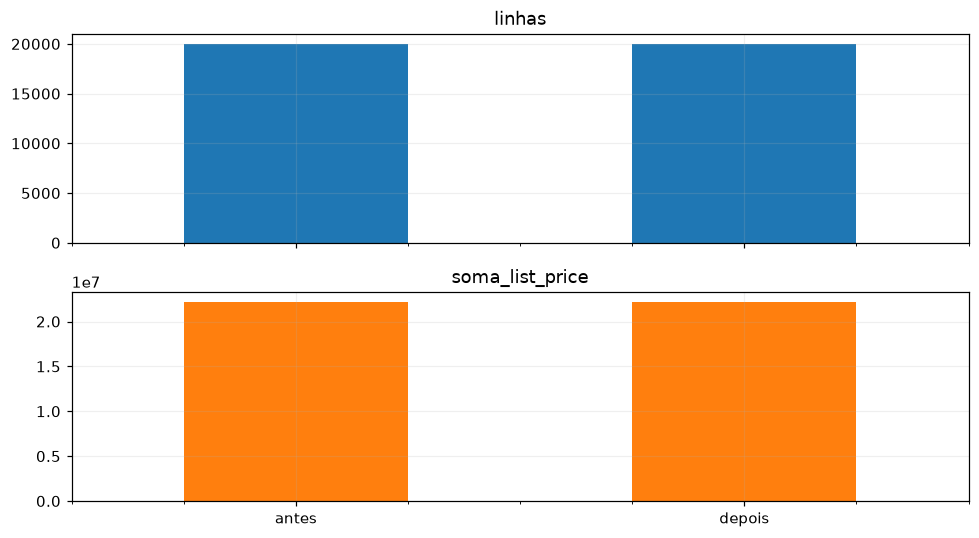

In [3]:
df_limpo = df.drop_duplicates().copy()
assert not df_limpo.transaction_id.duplicated().any(), 'Conflitos de ID exigem revisão'
impacto = pd.DataFrame({nome:{'linhas':len(base),'soma_list_price':base.list_price.sum(),'ticket_list_price':base.list_price.mean(),'duplicatas_excedentes':base.duplicated().sum()} for nome,base in {'antes':df,'depois':df_limpo}.items()}).T
display(impacto.round(2))
print('Registros removidos:',len(df)-len(df_limpo))
print('Variação na soma de list_price:',df_limpo.list_price.sum()-df.list_price.sum())
print('A soma de preços de lista não equivale necessariamente à receita realizada, pois existem status e custos distintos.')
impacto[['linhas','soma_list_price']].plot.bar(subplots=True,figsize=(9,5),rot=0,legend=False)
plt.tight_layout(); plt.show()
assert df.equals(original)
impacto.to_csv(RESULTADOS/'02_impacto.csv')

## Desafio — Similaridade textual e CustomerDemographic

In [4]:
from rapidfuzz import fuzz
from itertools import combinations
marcas = sorted(df.brand.dropna().astype(str).unique())
pares = pd.DataFrame([{'marca_a':a,'marca_b':b,'similaridade':fuzz.WRatio(a.casefold(),b.casefold())} for a,b in combinations(marcas,2)]).sort_values('similaridade',ascending=False)
display(pares.head(10))
print('Candidatas com similaridade >= 85:')
display(pares.query('similaridade >= 85'))
demo = pd.read_excel(arquivo,sheet_name='CustomerDemographic',header=0)
print('Cabeçalho CustomerDemographic:',demo.columns.tolist())
assert 'gender' in demo.columns
display(demo.gender.value_counts(dropna=False).rename('quantidade'))
gender_normalizado = demo.gender.astype('string').str.strip().str.casefold()
display(pd.DataFrame({'original':demo.gender,'normalizado':gender_normalizado}).drop_duplicates())
print('Categorias registradas:', demo.gender.nunique(dropna=False))

Candidatas com similaridade >= 85:
Cabeçalho CustomerDemographic: ['customer_id', 'name', 'gender', 'past_3_years_bike_related_purchases', 'DOB', 'age', 'job_title', 'job_industry_category', 'wealth_segment', 'deceased_indicator', 'owns_car', 'tenure']
Categorias registradas: 3


,marca_a,marca_b,similaridade
3,Giant Bicycles,Trek Bicycles,74.074074
7,Norco Bicycles,Trek Bicycles,74.074074
0,Giant Bicycles,Norco Bicycles,71.428571
5,Norco Bicycles,OHM Cycles,66.666667
10,OHM Cycles,Trek Bicycles,60.869565
1,Giant Bicycles,OHM Cycles,58.333333
2,Giant Bicycles,Solex,45.000000
9,OHM Cycles,Solex,45.000000
6,Norco Bicycles,Solex,45.000000
12,Solex,Trek Bicycles,45.000000


,marca_a,marca_b,similaridade


gender
Female    2039
Male      1873
U           88
Name: quantidade, dtype: int64

,original,normalizado
0,U,u
88,Male,male
89,Female,female


## Respostas às perguntas de reflexão
1. Zero duplicatas exatas não garante ausência de repetição de eventos: o mesmo evento pode ter um campo corrigido, ID novo ou texto diferente. Conferi também chaves e identificadores.
2. Em uma exportação sem ID e sem horário, duas compras reais de um mesmo item, pelo mesmo cliente, no mesmo dia, podem resultar em linhas idênticas. O evento de negócio define a duplicação; a aparência da linha não basta.
3. No Entendimento do Negócio do CRISP-DM, definiria se cada linha representa pedido, item ou pagamento. Um pedido com vários itens não deve ser reduzido a uma única linha por pedido sem consolidar corretamente os valores.
4. A versão baixada tem Female, Male e U em gênero. Não encontrei variantes como F ou Femal; U deve ser interpretado como categoria desconhecida, sem atribuir gênero por inferência. A normalização mostrada preserva a distinção.
5. RapidFuzz gera candidatos para inspeção, não prova identidade. Marcas distintas não devem ser unificadas só por um limiar de similaridade. Nesta base mantenho as categorias originais quando não há evidência adicional.

Referência: [RapidFuzz — comparadores de texto](https://rapidfuzz.github.io/RapidFuzz/Usage/fuzz.html).

## Síntese dos resultados executados

As 20,000 transações permaneceram, com soma de preços de lista 22,156,588.98. Não há repetição na chave candidata examinada nem nos IDs; portanto o impacto da deduplicação é zero. O par de marcas com maior similaridade também representa nomes diferentes e foi preservado.